# Week 3 — What is a good model? From scores to decisions
**AI in Business · MSc Business Analytics and AI · UMT**

Last week you built a hand-made risk score and found that your top 200 customers churned at about 74%.
Today we answer the real question: **should we call them, and how many?**

| Part | Topic | Book |
|---|---|---|
| A | Train/test split and the base-rate trap | ch. 7 |
| B | A real model (logistic regression) and the confusion matrix | ch. 7 |
| C | Expected value: choosing a threshold by profit | ch. 7 |
| D | Ranking: profit, lift and ROC curves | ch. 8 |
| E | What if our assumptions are wrong? | ch. 8 |

In [1]:
# Install all the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# DOnt install the enotre sklearn, only modules we eill use
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
# Set a bunch of plotting parameters and colors (change as you like)
plt.rcParams.update({"figure.figsize": (7, 4), 
                     "axes.spines.top": False,
                     "axes.spines.right": False, 
                     "axes.grid": True, 
                     "grid.alpha": 0.3})
# Set colors for models: hand-made score / random
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#7a7a7a"

## Load and clean the data (same steps as week 2)

In [3]:
LOCAL = Path("telco_churn.csv")
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Change TotalCharges to numeric and fix some NAs (go back to week 2)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["churned"] = (df["Churn"] == "Yes").astype(int)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
print(df.shape, "| base churn rate:", round(df["churned"].mean(), 3))

(7043, 22) | base churn rate: 0.265


# Part A — Test on data the model has never seen

In the book's churn case (ch. 8), k-nearest neighbour scored **100%** accuracy on the data it was trained on, and only 93% (the base rate) on new data. It had memorised, not learned.

So we split the customers: the model learns from **70%** (training set) and we judge it only on the other **30%** (test set).

`stratify=y` keeps the same churn rate in both parts.

In [6]:
# Target: 1/0
y = df["churned"].to_numpy()

# Convert all classes into dummies, remove customerID", "Churn", "churned" because we dont need them anymore
X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "churned"]), drop_first=True).astype(float)

X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,29.85,29.85,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.0,34.0,56.95,1889.50,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,2.0,53.85,108.15,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.0,45.0,42.30,1840.75,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,2.0,70.70,151.65,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [7]:
# Split the data into Train/Test
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(X, y, df, test_size=0.3, random_state=42, stratify=y)

print("Training customers:", len(y_train), "| churn rate", round(y_train.mean(), 3))
print("Test customers:    ", len(y_test), "| churn rate", round(y_test.mean(), 3))
print("Features after one-hot encoding:", X.shape[1])

Training customers: 4930 | churn rate 0.265
Test customers:     2113 | churn rate 0.265
Features after one-hot encoding: 30


## The baseline
The simplest "model" predicts that **nobody churns**. What accuracy does it get on the test set? Write it down: every model must beat it.

In [8]:
# predicting 0 for everyone is right for every stayer
majority_accuracy = (y_test == 0).mean()
print(f"'Nobody churns' accuracy: {majority_accuracy:.1%}")

'Nobody churns' accuracy: 73.5%


# Part B — A real model and its confusion matrix

**Logistic regression** is, for us today, a black box with one job: give every customer a **probability of churning**.
Inside, it is last week's idea: a weighted score `X @ w` (a dot product), squeezed into a number between 0 and 1. The difference is that the **weights are learned from the training data**, not chosen by hand.

In [9]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
# learn the weights from the training set only
model.fit(X_train, y_train)

# probability of churn for each test customer
p_churn = model.predict_proba(X_test)[:, 1]
p_churn

array([0.58965579, 0.03334906, 0.76121829, ..., 0.03840077, 0.56271934,
       0.03305008], shape=(2113,))

In [10]:
# Convert it into a dataframe
preview = df_test[["customerID", "Contract", "tenure", "MonthlyCharges", "Churn"]].copy()
preview["p_churn"] = p_churn.round(2)
preview.sort_values("p_churn", ascending=False).head(8)

,customerID,Contract,tenure,MonthlyCharges,Churn,p_churn
3380,5178-LMXOP,Month-to-month,1,95.10,Yes,0.85
6866,0295-PPHDO,Month-to-month,1,95.45,Yes,0.83
2631,6861-XWTWQ,Month-to-month,7,99.25,Yes,0.82
3346,2545-EBUPK,Month-to-month,2,84.05,No,0.82
4585,1069-XAIEM,Month-to-month,1,85.05,Yes,0.82
6365,8884-ADFVN,Month-to-month,7,101.95,Yes,0.81
4039,8161-QYMTT,Month-to-month,7,94.10,No,0.81
3727,9057-SIHCH,Month-to-month,3,96.60,Yes,0.81


Which features push the score up or down? The learned weights (on standardized features, so they are comparable):

In [11]:
weights = pd.Series(model[-1].coef_[0], index=X.columns).sort_values()
pd.concat([weights.head(5), weights.tail(5)]).round(2)

tenure                        -1.32
MonthlyCharges                -0.71
Contract_Two year             -0.57
Contract_One year             -0.30
OnlineSecurity_Yes            -0.14
MultipleLines_Yes              0.20
PaperlessBilling_Yes           0.20
StreamingMovies_Yes            0.24
InternetService_Fiber optic    0.63
TotalCharges                   0.64
dtype: float64

> **Careful:** these weights are not causes. `tenure`, `MonthlyCharges` and `TotalCharges` move together (TotalCharges ≈ tenure × MonthlyCharges), so the model splits their effect in odd ways (e.g. a negative weight on `MonthlyCharges` even though churners pay more). Use the model to **rank**, not to explain. This is something to be explored in more advanced cases, maybe later

## The confusion matrix

A probability is not yet a decision. Software (including scikit-learn's `predict`) uses a **50% threshold** by default: predict "churn" if p ≥ 0.5.
The helper below lays out the matrix as in the book: rows = predicted (Y/N), columns = actual (p/n).

In [12]:
def confusion(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum()); fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum()); tn = int(((y_pred == 0) & (y_true == 0)).sum())
    return pd.DataFrame([[tp, fp], [fn, tn]], index=["Y (predict churn)", "N (predict stay)"],
                        columns=["p (churned)", "n (stayed)"])

pred_50 = (p_churn >= 0.5).astype(int)
cm_50 = confusion(y_test, pred_50)
cm_50

,p (churned),n (stayed)
Y (predict churn),316,158
N (predict stay),245,1394


## Exercise — Read the matrix
From `cm_50`, compute:
1. Accuracy. How much better than the baseline of Exercise 1?
2. **Hit rate** (true positive rate): share of real churners we flag.
3. **False alarm rate** (false positive rate): share of stayers we flag.
4. **Precision**: of the customers we flag, what share really churn?

In [13]:
tp, fp = cm_50.iloc[0, 0], cm_50.iloc[0, 1]
fn, tn = cm_50.iloc[1, 0], cm_50.iloc[1, 1]
accuracy = (tp + tn) / (tp + fp + fn + tn)
hit_rate = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)
precision = tp / (tp + fp)
print(f"Accuracy {accuracy:.1%}  (baseline {(y_test == 0).mean():.1%})")
print(f"Hit rate {hit_rate:.1%} | false alarm rate {false_alarm_rate:.1%} | precision {precision:.1%}")

Accuracy 80.9%  (baseline 73.5%)
Hit rate 56.3% | false alarm rate 10.2% | precision 66.7%


> Accuracy improved by only about 7 points over doing nothing, and we still miss almost half of the churners. Is the model useless? We cannot tell yet: **we have not said what each kind of error costs.**

# Part C — Expected value: decide by profit, not accuracy

## Our cost-benefit assumptions
The data cannot tell us these. They come from the business (illustrative numbers):

- A retention call plus discount costs **€20**.
- A churner who gets the call stays **1 time in 4**; a saved customer is worth **€240** of future margin.
- A stayer who gets the call stays anyway: we wasted €20.

So, in the book's notation:

| | actual churner (p) | actual stayer (n) |
|---|---|---|
| **Y** (we call) | b(Y,p) = 0.25 × 240 − 20 = **+€40** | b(Y,n) = **−€20** |
| **N** (no call) | b(N,p) = **€0** | b(N,n) = **€0** |

In [14]:
# € per call
OFFER_COST = 20
# share of called churners who stay
SAVE_RATE = 0.25
# € future margin of a saved customer
CUSTOMER_VALUE = 240

# Lets create a matrix
def benefits(offer_cost=OFFER_COST, save_rate=SAVE_RATE, value=CUSTOMER_VALUE):
    return {"TP": save_rate * value - offer_cost, "FP": -offer_cost, "FN": 0.0, "TN": 0.0}

B = benefits()
print(B)

{'TP': 40.0, 'FP': -20, 'FN': 0.0, 'TN': 0.0}


In [15]:
# Lets calculate the expected profits
def expected_profit(cm, b):
    # Expected profit per customer = sum over cells of p(cell) x benefit(cell)  (book eq. 7-1)
    n = cm.to_numpy().sum()
    return (cm.iloc[0, 0] * b["TP"] + cm.iloc[0, 1] * b["FP"]
            + cm.iloc[1, 0] * b["FN"] + cm.iloc[1, 1] * b["TN"]) / n

## Exercise 3
What is the expected profit **per 1,000 customers** if we call everyone the model flags at the 50% threshold?
And if we call **everyone**? (Hint: calling everyone is the confusion matrix of `np.ones_like(y_test)`.)

In [16]:
ev_50 = expected_profit(cm_50, B) * 1000
ev_all = expected_profit(confusion(y_test, np.ones_like(y_test)), B) * 1000
print(f"Model at 50% threshold: €{ev_50:,.0f} per 1,000 customers")
print(f"Call everyone:          €{ev_all:,.0f} per 1,000 customers")

Model at 50% threshold: €4,487 per 1,000 customers
Call everyone:          €-4,070 per 1,000 customers


## The threshold that expected value suggests

Call a customer if the expected value of calling is positive:

$$ p \times 40 \;+\; (1-p) \times (-20) \;>\; 0 $$

## Exercise 4
1. Solve for p on paper. (Same algebra as the €38 / €2 offer in class.)
2. Compute the expected profit per 1,000 customers at that threshold and compare it with the 50% threshold.

In [17]:
# 40p - 20(1 - p) > 0  ->  60p > 20  ->  p > 1/3
threshold_ev = 20 / 60
cm_ev = confusion(y_test, (p_churn >= threshold_ev).astype(int))
print(f"EV threshold = {threshold_ev:.3f}")
print(cm_ev, "\n")
print(f"Profit at 50% threshold:  €{expected_profit(cm_50, B) * 1000:,.0f} per 1,000")
print(f"Profit at EV threshold:   €{expected_profit(cm_ev, B) * 1000:,.0f} per 1,000")

EV threshold = 0.333
                   p (churned)  n (stayed)
Y (predict churn)          411         347
N (predict stay)           150        1205 

Profit at 50% threshold:  €4,487 per 1,000
Profit at EV threshold:   €4,496 per 1,000


Let's check by brute force: try every threshold and plot the profit.

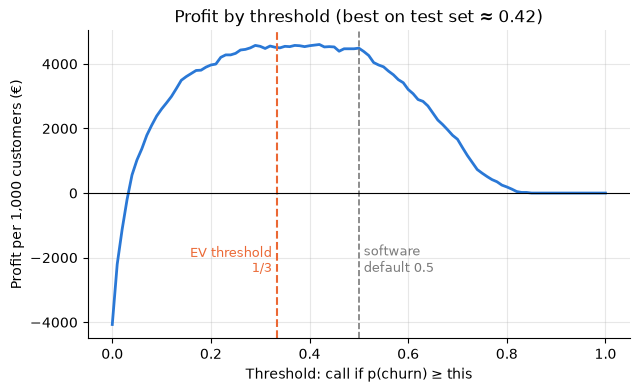

In [18]:
thresholds = np.linspace(0, 1, 101)
profits = [expected_profit(confusion(y_test, (p_churn >= t).astype(int)), B) * 1000 for t in thresholds]
best_t = thresholds[int(np.argmax(profits))]

fig, ax = plt.subplots()
ax.plot(thresholds, profits, color=BLUE, linewidth=2)
ax.axvline(0.5, color=GREY, linestyle="--", linewidth=1.2)
ax.axvline(1 / 3, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(0.51, min(profits) * 0.6, "software\ndefault 0.5", color=GREY, fontsize=9)
ax.text(1 / 3 - 0.01, min(profits) * 0.6, "EV threshold\n1/3", color=ORANGE, fontsize=9, ha="right")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Threshold: call if p(churn) ≥ this")
ax.set_ylabel("Profit per 1,000 customers (€)")
ax.set_title(f"Profit by threshold (best on test set ≈ {best_t:.2f})")
plt.show()

> **Key point.** The best threshold comes from the costs and benefits, not from 50%. Notice the **flat top**: on this test set, thresholds between about 0.3 and 0.5 give similar profit, so the brute-force "best" is partly noise. Below the EV threshold, profit falls fast; at 0 (call everyone) we lose money.

# Part D — Ranking: profit, lift and ROC curves

Often we have a **budget** ("we can make N calls") rather than a threshold. Then we **rank** customers by score and work down the list.
We compare three rankings:

1. **Logistic regression** (the model)
2. **Your hand-made score from week 2** (the baseline, using the week 2 solution weights; replace them with yours)
3. **Random order**

In [19]:
F = np.column_stack([
    df_test["Contract"] == "Month-to-month",
    df_test["InternetService"] == "Fiber optic",
    df_test["PaymentMethod"] == "Electronic check",
    df_test["tenure"] <= 12,
    df_test["SeniorCitizen"] == 1,
    df_test["TechSupport"] == "No",
]).astype(float)

# <- put your own week 2 weights here
hand_weights = np.array([3, 2, 2, 2, 1, 1])

# Many customers share the same hand-made score; a tiny random jitter breaks ties fairly
rng = np.random.default_rng(0)
s_hand = F @ hand_weights + rng.uniform(0, 1e-3, len(y_test))
s_random = rng.uniform(size=len(y_test))

## D1. Profit curve

Sort customers by score, highest first, and compute the profit of calling the top 0%, 1%, …, 100%.

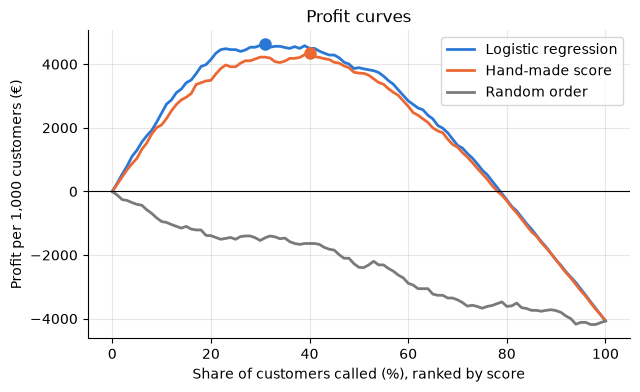

Logistic regression  best: call top 31% -> €4,619 per 1,000
Hand-made score      best: call top 40% -> €4,354 per 1,000


In [20]:
def ranking_curves(y_true, score, b=B):
    order = np.argsort(-score)
    hits = y_true[order]
    n, n_pos = len(hits), hits.sum()
    # churners reached after k calls
    cum_tp = np.concatenate([[0], np.cumsum(hits)])
    # stayers called after k calls
    cum_fp = np.concatenate([[0], np.cumsum(1 - hits)])
    pct = np.arange(101)
    k = np.round(pct / 100 * n).astype(int)
    profit = (cum_tp[k] * b["TP"] + cum_fp[k] * b["FP"]) / n * 1000
    cum_resp = cum_tp[k] / n_pos * 100
    return pd.DataFrame({"pct": pct, "profit": profit, "cum_resp": cum_resp})

curves = {"Logistic regression": ranking_curves(y_test, p_churn),
          "Hand-made score": ranking_curves(y_test, s_hand),
          "Random order": ranking_curves(y_test, s_random)}
colors = {"Logistic regression": BLUE, "Hand-made score": ORANGE, "Random order": GREY}

fig, ax = plt.subplots()
for name, c in curves.items():
    ax.plot(c["pct"], c["profit"], color=colors[name], linewidth=2, label=name)
    if name != "Random order":
        i = c["profit"].idxmax()
        ax.plot(c.loc[i, "pct"], c.loc[i, "profit"], "o", color=colors[name], markersize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Share of customers called (%), ranked by score")
ax.set_ylabel("Profit per 1,000 customers (€)")
ax.set_title("Profit curves")
ax.legend()
plt.show()

for name in ["Logistic regression", "Hand-made score"]:
    c = curves[name]; i = c["profit"].idxmax()
    print(f"{name:20s} best: call top {c.loc[i, 'pct']}% -> €{c.loc[i, 'profit']:,.0f} per 1,000")

## Exercise 5 — a budget
The budget allows calls to only **10%** of customers. Which ranking would you use, and what profit do you expect per 1,000 customers?
What does it cost us to use the hand-made score instead of the model, for a base of **100,000** customers?

In [21]:
lr10 = curves["Logistic regression"].loc[10, "profit"]
hand10 = curves["Hand-made score"].loc[10, "profit"]
print(f"At 10%: model €{lr10:,.0f}, hand-made €{hand10:,.0f} per 1,000 customers")
print(f"Difference for 100,000 customers: €{(lr10 - hand10) * 100:,.0f}")

At 10%: model €2,461, hand-made €2,092 per 1,000 customers
Difference for 100,000 customers: €36,914


## D2. Cumulative response and lift: no costs needed

The **cumulative response curve** shows what share of all churners we reach as we go down the list.
**Lift** = that share ÷ the share we would reach at random (= the share of the list called).

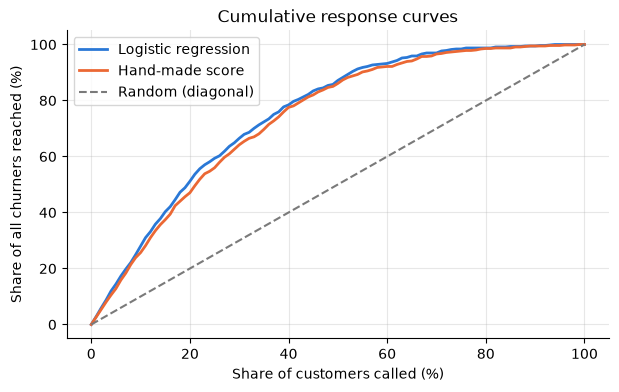

In [22]:
fig, ax = plt.subplots()
for name, c in curves.items():
    if name == "Random order":
        ax.plot([0, 100], [0, 100], color=GREY, linewidth=1.5, linestyle="--", label="Random (diagonal)")
    else:
        ax.plot(c["pct"], c["cum_resp"], color=colors[name], linewidth=2, label=name)
ax.set_xlabel("Share of customers called (%)")
ax.set_ylabel("Share of all churners reached (%)")
ax.set_title("Cumulative response curves")
ax.legend()
plt.show()

## Exercise 6
Compute the **lift** of both rankings at 10% and 20% of the list. Complete the sentence: *"The top 10% of the model's list contains __% of all churners, a lift of __."*

In [23]:
for name in ["Logistic regression", "Hand-made score"]:
    c = curves[name]
    for pct in (10, 20):
        reached = c.loc[pct, "cum_resp"]
        print(f"{name:20s} top {pct}%: reaches {reached:.0f}% of churners, lift {reached / pct:.2f}")

Logistic regression  top 10%: reaches 28% of churners, lift 2.80
Logistic regression  top 20%: reaches 51% of churners, lift 2.56
Hand-made score      top 10%: reaches 26% of churners, lift 2.57
Hand-made score      top 20%: reaches 47% of churners, lift 2.35


## D3. ROC curve and AUC

The ROC curve plots **hit rate** (share of churners flagged) against **false alarm rate** (share of stayers flagged) for every possible cut-off.
It does not depend on costs or on the share of churners. **AUC** is the probability that a random churner is ranked above a random stayer: 0.5 = guessing, 1 = perfect.

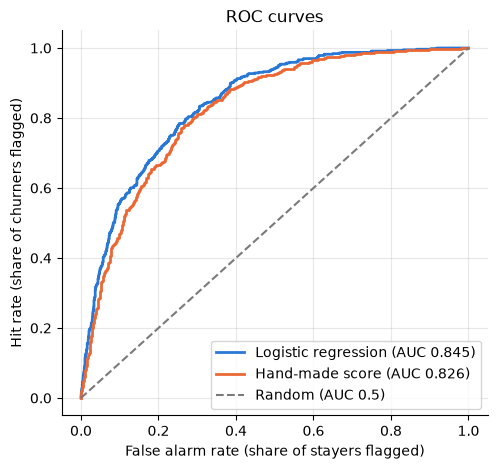

In [24]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, score in [("Logistic regression", p_churn), ("Hand-made score", s_hand)]:
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, color=colors[name], linewidth=2,
            label=f"{name} (AUC {roc_auc_score(y_test, score):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1.5, label="Random (AUC 0.5)")
ax.set_xlabel("False alarm rate (share of stayers flagged)")
ax.set_ylabel("Hit rate (share of churners flagged)")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.show()

> The model beats your hand-made score, but not by much. A simple, sensible baseline is often hard to beat (ch. 7). Before buying a complex model, always ask: **how much better than the simple rule, in euros?**

# Part E — What if our assumptions are wrong?

The costs and the save rate are guesses. Profit curves are only as good as these guesses, so check how sensitive the decision is.

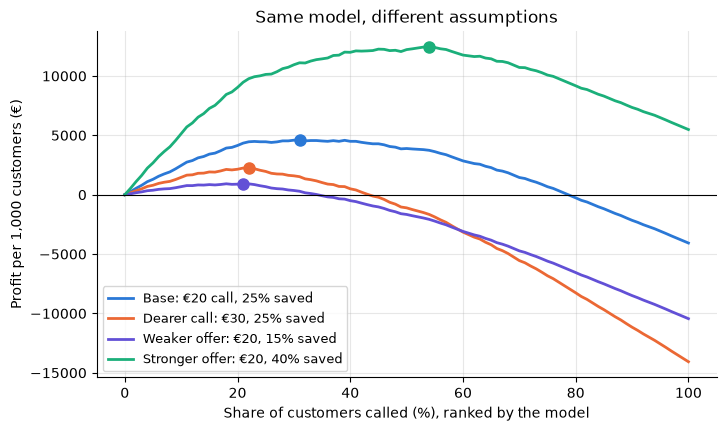

,scenario,TP benefit (€),best % to call,"profit per 1,000 (€)"
0,"Base: €20 call, 25% saved",40.0,31,4619
1,"Dearer call: €30, 25% saved",30.0,22,2257
2,"Weaker offer: €20, 15% saved",16.0,21,926
3,"Stronger offer: €20, 40% saved",76.0,54,12462


In [25]:
scenarios = {
    "Base: €20 call, 25% saved": benefits(20, 0.25),
    "Dearer call: €30, 25% saved": benefits(30, 0.25),
    "Weaker offer: €20, 15% saved": benefits(20, 0.15),
    "Stronger offer: €20, 40% saved": benefits(20, 0.40),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
rows = []
for (name, b), col in zip(scenarios.items(), ["#2a78d6", "#eb6834", "#6250d6", "#1baf7a"]):
    c = ranking_curves(y_test, p_churn, b)
    i = c["profit"].idxmax()
    ax.plot(c["pct"], c["profit"], linewidth=2, color=col, label=name)
    ax.plot(c.loc[i, "pct"], c.loc[i, "profit"], "o", color=col, markersize=8)
    rows.append({"scenario": name, "TP benefit (€)": b["TP"], "best % to call": c.loc[i, "pct"],
                 "profit per 1,000 (€)": round(c.loc[i, "profit"])})
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Share of customers called (%), ranked by the model")
ax.set_ylabel("Profit per 1,000 customers (€)")
ax.set_title("Same model, different assumptions")
ax.legend(fontsize=9)
plt.show()
pd.DataFrame(rows)

## Exercise 7
1. When the call gets dearer, does the best cut-off move up or down the list? Why?
2. Which assumption matters most for the decision? Who in the company should you ask to pin it down?
3. Try your own scenario with `benefits(offer_cost, save_rate, value)`. Is there a scenario where calling **nobody** is best?

In [26]:
# 1. Dearer call -> false positives cost more -> we stop earlier (call fewer people).
# 2. The save rate (and customer value) drive the TP benefit; ask marketing/finance,
#    ideally test it with an experiment (week 7).
# 3. If save_rate * value <= offer_cost, every call loses money: call nobody.
my_b = benefits(offer_cost=20, save_rate=0.08, value=240)   # 0.08 * 240 = 19.2 < 20
c = ranking_curves(y_test, p_churn, my_b)
print(my_b)
print("Best share to call:", c.loc[c["profit"].idxmax(), "pct"], "%")

{'TP': -0.8000000000000007, 'FP': -20, 'FN': 0.0, 'TN': 0.0}
Best share to call: 0 %


---
## Discussion (5 minutes)

- Our expected-value calculation assumes the offer works **equally on every churner** (25%). Is that realistic? Who is more likely to be persuaded: a customer leaving for a cheaper competitor, or one who is moving abroad?
- A churn model tells us **who will leave**, not **whose mind a call can change**. That is the difference between prediction and causation: the "persuadables" from week 1. We come back to it in the causal analysis week.

---
# Exit ticket (on paper)

**Q1.** A model has 85% accuracy where 85% of customers do not churn. What can you conclude?

**Q2.** A call costs €10. A churner who gets the call is saved with probability 0.2 and is worth €300. Above what churn probability should you call?

**Q3.** Your manager can only afford 5% of the list. Which chart do you look at, and where?

**Answers**

- **Q1.** Nothing yet: "nobody churns" also gets 85%. Look at the confusion matrix and the costs.
- **Q2.** TP benefit = 0.2 × 300 − 10 = €50; FP = −€10. Call if 50p − 10(1 − p) > 0 → 60p > 10 → **p > 1/6 ≈ 16.7%**.
- **Q3.** The profit curve (or, without costs, the lift / cumulative response curve) **at x = 5%**: choose the ranking that is highest there, not the one with the highest peak.